# Find DELVE raw inputs in an RA/Dec range
Selects DELVE exposures from the DELVE DR3 QR combo CSV for one sky chunk (an RA/Dec box) and checks each against the
existing incremental-template mask (`incremental_gen/[band]_template_fraction.npy`, the fraction of each HEALPix pixel
that already has >= N incremental templates). The chunk's planned template footprint is the **unmasked** part of the box
(no existing template coverage), grown by `TEMPLATE_GROW_DEG`; by default only exposures centred in that grown footprint
are kept, so the planned templates keep their depth up to their edges. Optionally looks up the raw-image md5sums in the
NOIRLab astro data archive.

In [1]:
import os, json
import numpy as np
import pandas as pd
import healpy as hp
import matplotlib.pyplot as plt

## Inputs

In [4]:
DELVE_CSV = "../data/delve_dr3qr_combo_v10.csv"
MASK_DIR = "incremental_gen"
OUT_DIR = "out_patch0"

# RA/Dec box in degrees. RA may wrap through 0 (e.g. RA_RANGE = (350, 10)).
RA_RANGE = (300.0, 330.0)
DEC_RANGE = (-60, -30)
DEC_RANGE = (-90, -60)
DEC_RANGE = (-30, 0)
DEC_RANGE = (0, 50)

BANDS = ["g", "r", "i", "z"]       # bands to include
FRACTION_THRESHOLD = 0.1           # a pixel is masked (template exists) if fraction > this
FOOTPRINT_RADIUS_DEG = 1.1        # approx DECam field radius; an exposure touches every pixel within this of its centre
TEMPLATE_GROW_DEG = 1.1           # grow the planned template footprint by this, at the chunk perimeter and around enclosed holes
FOOTPRINT_NSIDE = 512             # nside of the planned footprint; finer than the masks so the box edges and growth resolve
SELECTION = "unmasked"            # "unmasked": exposures centred in the grown planned-template footprint; "masked": the opposite; "all"
QUERY_NOIRLAB = True              # True: look up raw-file md5sums for the selected expnums

## Load template masks

In [5]:
fraction = {b: np.load(os.path.join(MASK_DIR, f"[{b}]_template_fraction.npy")) for b in BANDS}
mask = {b: np.load(os.path.join(MASK_DIR, f"[{b}]_template_mask.npy")) for b in BANDS}
nside = {hp.npix2nside(len(fraction[b])) for b in BANDS}
assert len(nside) == 1, f"inconsistent nside across bands: {nside}"
NSIDE = nside.pop()
with open(os.path.join(MASK_DIR, "metadata.json")) as f:
    print(json.load(f))
print("nside =", NSIDE)

{'incremental_dir': '/sdf/home/e/ebellm/u/workspace/incremental_templates/template_tools/output_incremental_test', 'file_pattern': '8_*/incremental_template_inputs_8_*{band}_inputs.hsp', 'bands': ['[i]'], 'nside': 64, 'n_template_threshold': 5, 'exist_threshold': 0.0, 'count_key': None, 'vector_reduction': 'sum', 'created_utc': '2026-10-01T04:32:09.905346+00:00'}
nside = 64


## Planned template footprint
In each band the chunk's planned template footprint is the part of the RA/Dec box without existing templates
(fraction <= `FRACTION_THRESHOLD`), on a `FOOTPRINT_NSIDE` grid. It is grown by `TEMPLATE_GROW_DEG` at every edge: outward
across the chunk perimeter, and into any masked holes it encloses (e.g. bright-star masks inside a wider template region).
Exposures centred in the grown footprint therefore include those centred just outside the planned templates that still
overlap their edges, which would otherwise be dropped and leave the template edges short of inputs.

In [6]:
def in_ra_dec_box(ra, dec):
    ra, lo, hi = ra % 360, RA_RANGE[0] % 360, RA_RANGE[1] % 360
    if (RA_RANGE[1] - RA_RANGE[0]) >= 360:
        in_ra = np.ones(len(ra), dtype=bool)
    else:
        in_ra = (ra >= lo) & (ra <= hi) if lo <= hi else (ra >= lo) | (ra <= hi)
    return in_ra & (dec >= DEC_RANGE[0]) & (dec <= DEC_RANGE[1])

def grow(footprint, radius_deg):
    """Every pixel within radius_deg of a bool HEALPix footprint, so its outer edge and the edges of its holes grow alike."""
    nside = hp.npix2nside(len(footprint))
    inside = np.flatnonzero(footprint)
    nbrs = hp.get_all_neighbours(nside, inside)  # -1 where a pixel has only 7 neighbours
    edge = inside[((nbrs >= 0) & ~footprint[nbrs]).any(axis=0)]
    grown = footprint.copy()
    for vec in np.transpose(hp.pix2vec(nside, edge)):
        grown[hp.query_disc(nside, vec, np.deg2rad(radius_deg), inclusive=True)] = True
    return grown

pix_ra, pix_dec = hp.pix2ang(FOOTPRINT_NSIDE, np.arange(hp.nside2npix(FOOTPRINT_NSIDE)), lonlat=True)
box = in_ra_dec_box(pix_ra, pix_dec)
planned = {b: box & (hp.ud_grade(fraction[b], FOOTPRINT_NSIDE) <= FRACTION_THRESHOLD) for b in BANDS}
grown = {b: grow(planned[b], TEMPLATE_GROW_DEG) for b in BANDS}
grown_box = grow(box, TEMPLATE_GROW_DEG)

pix_area = hp.nside2pixarea(FOOTPRINT_NSIDE, degrees=True)
print(f"box: {box.sum() * pix_area:.0f} deg2 -> {grown_box.sum() * pix_area:.0f} deg2 grown")
for b in BANDS:
    print(f"{b}: planned {planned[b].sum() * pix_area:.0f} deg2 -> {grown[b].sum() * pix_area:.0f} deg2 grown")

box: 1318 deg2 -> 1492 deg2 grown
g: planned 1318 deg2 -> 1492 deg2 grown
r: planned 1318 deg2 -> 1492 deg2 grown
i: planned 1304 deg2 -> 1490 deg2 grown
z: planned 1306 deg2 -> 1490 deg2 grown


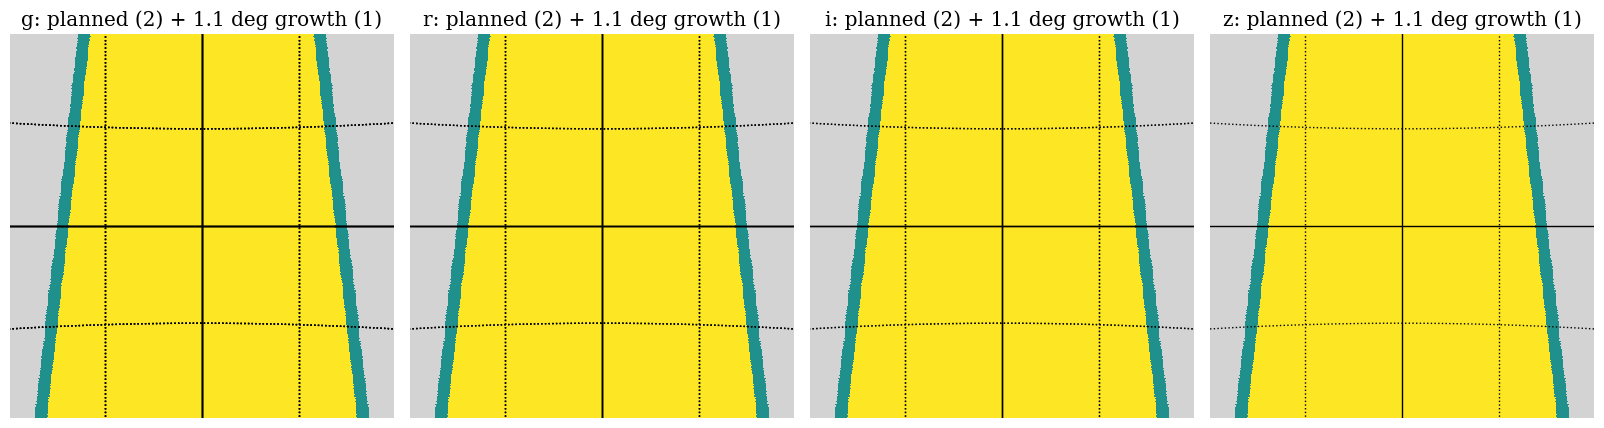

In [7]:
view_deg = 40  # width of each panel, enough for a 30 deg chunk plus its growth
ra_width = (RA_RANGE[1] - RA_RANGE[0]) % 360 or 360
centre = ((RA_RANGE[0] + ra_width / 2) % 360, np.mean(DEC_RANGE))
fig = plt.figure(figsize=(16, 4.5))
for k, b in enumerate(BANDS, start=1):
    m = planned[b] + grown[b].astype(float)
    m[m == 0] = hp.UNSEEN
    hp.gnomview(m, rot=centre, xsize=500, reso=view_deg * 60 / 500, fig=fig.number, sub=(1, len(BANDS), k),
                title=f"{b}: planned (2) + {TEMPLATE_GROW_DEG} deg growth (1)", min=0, max=2, cmap="viridis",
                badcolor="lightgrey", cbar=False, notext=True)
    hp.graticule(dpar=10, dmer=10)

## Load DELVE exposures and select RA/Dec range

In [8]:
delve = pd.read_csv(DELVE_CSV)
delve = delve[delve["band"].isin(BANDS)].copy()

# exposures centred within TEMPLATE_GROW_DEG of the chunk's RA/Dec box
fine_pix = hp.ang2pix(FOOTPRINT_NSIDE, delve["ra"].values, delve["dec"].values, lonlat=True)
sel_df = delve[grown_box[fine_pix]].copy()
print(f"{len(sel_df)} of {len(delve)} DELVE exposures within {TEMPLATE_GROW_DEG} deg of RA {RA_RANGE}, Dec {DEC_RANGE}")

3949 of 210989 DELVE exposures within 1.1 deg of RA (300.0, 330.0), Dec (0, 50)


## Label with template fraction
Each exposure's footprint (all HEALPix pixels within `FOOTPRINT_RADIUS_DEG` of its centre) is checked against the mask
for its own band. `template_fraction_max` / `template_fraction_mean` summarise the footprint; an exposure is `template_masked`
if any footprint pixel has fraction > `FRACTION_THRESHOLD`. The centre-pixel fraction is kept as `template_fraction`.
`in_template_footprint` marks exposures centred in their band's grown planned-template footprint. These are what
`SELECTION = "unmasked"` keeps, including edge exposures that are partly `template_masked`.

In [9]:

radius = np.deg2rad(FOOTPRINT_RADIUS_DEG)
footprints = [
    hp.query_disc(NSIDE, hp.ang2vec(ra, dec, lonlat=True), radius, inclusive=True)
    for ra, dec in zip(sel_df["ra"].values, sel_df["dec"].values)
]
sel_df["hpx"] = hp.ang2pix(NSIDE, sel_df["ra"].values, sel_df["dec"].values, lonlat=True)
sel_df["template_fraction"] = np.nan        # centre pixel
sel_df["template_fraction_max"] = np.nan    # over footprint
sel_df["template_fraction_mean"] = np.nan
for b in BANDS:
    for i in np.flatnonzero((sel_df["band"] == b).values):
        vals = fraction[b][footprints[i]]
        sel_df.iloc[i, sel_df.columns.get_loc("template_fraction_max")] = vals.max()
        sel_df.iloc[i, sel_df.columns.get_loc("template_fraction_mean")] = vals.mean()
        sel_df.iloc[i, sel_df.columns.get_loc("template_fraction")] = fraction[b][sel_df["hpx"].iloc[i]]
sel_df["template_masked"] = sel_df["template_fraction_max"] > FRACTION_THRESHOLD
fine_pix = hp.ang2pix(FOOTPRINT_NSIDE, sel_df["ra"].values, sel_df["dec"].values, lonlat=True)
sel_df["in_template_footprint"] = [grown[b][p] for b, p in zip(sel_df["band"].values, fine_pix)]

print(sel_df.groupby("band").agg(n_exposures=("band", "size"), n_masked=("template_masked", "sum"),
                                 n_in_footprint=("in_template_footprint", "sum")))
footprints = dict(zip(sel_df.index, footprints))
if SELECTION == "unmasked":
    sel_df = sel_df[sel_df["in_template_footprint"]]
elif SELECTION == "masked":
    sel_df = sel_df[~sel_df["in_template_footprint"]]
print(f"{len(sel_df)} exposures kept (SELECTION={SELECTION!r})")


      n_exposures  n_masked  n_in_footprint
band                                       
g            1016         0            1016
i             915       176             908
r            1100        29            1100
z             918       131             912
3936 exposures kept (SELECTION='unmasked')


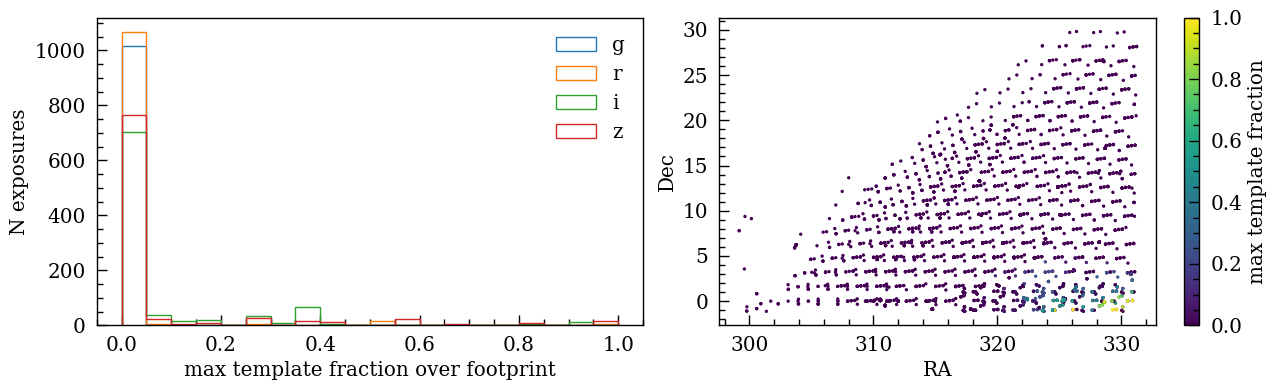

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for b in BANDS:
    s = sel_df[sel_df["band"] == b]
    axes[0].hist(s["template_fraction_max"], bins=np.linspace(0, 1, 21), histtype="step", label=b)
axes[0].set(xlabel="max template fraction over footprint", ylabel="N exposures"); axes[0].legend()
sc = axes[1].scatter(sel_df["ra"], sel_df["dec"], c=sel_df["template_fraction_max"], s=2, vmin=0, vmax=1)
plt.colorbar(sc, ax=axes[1], label="max template fraction"); axes[1].set(xlabel="RA", ylabel="Dec")
plt.tight_layout()

## Mollweide map of unmasked DELVE inputs
Number of DELVE exposures covering each HEALPix pixel (full footprint, not just centres), for the exposures kept by `SELECTION`
(by default those centred in the grown planned-template footprint). Pixels with no inputs are grey.

3936 exposures kept (SELECTION='unmasked')


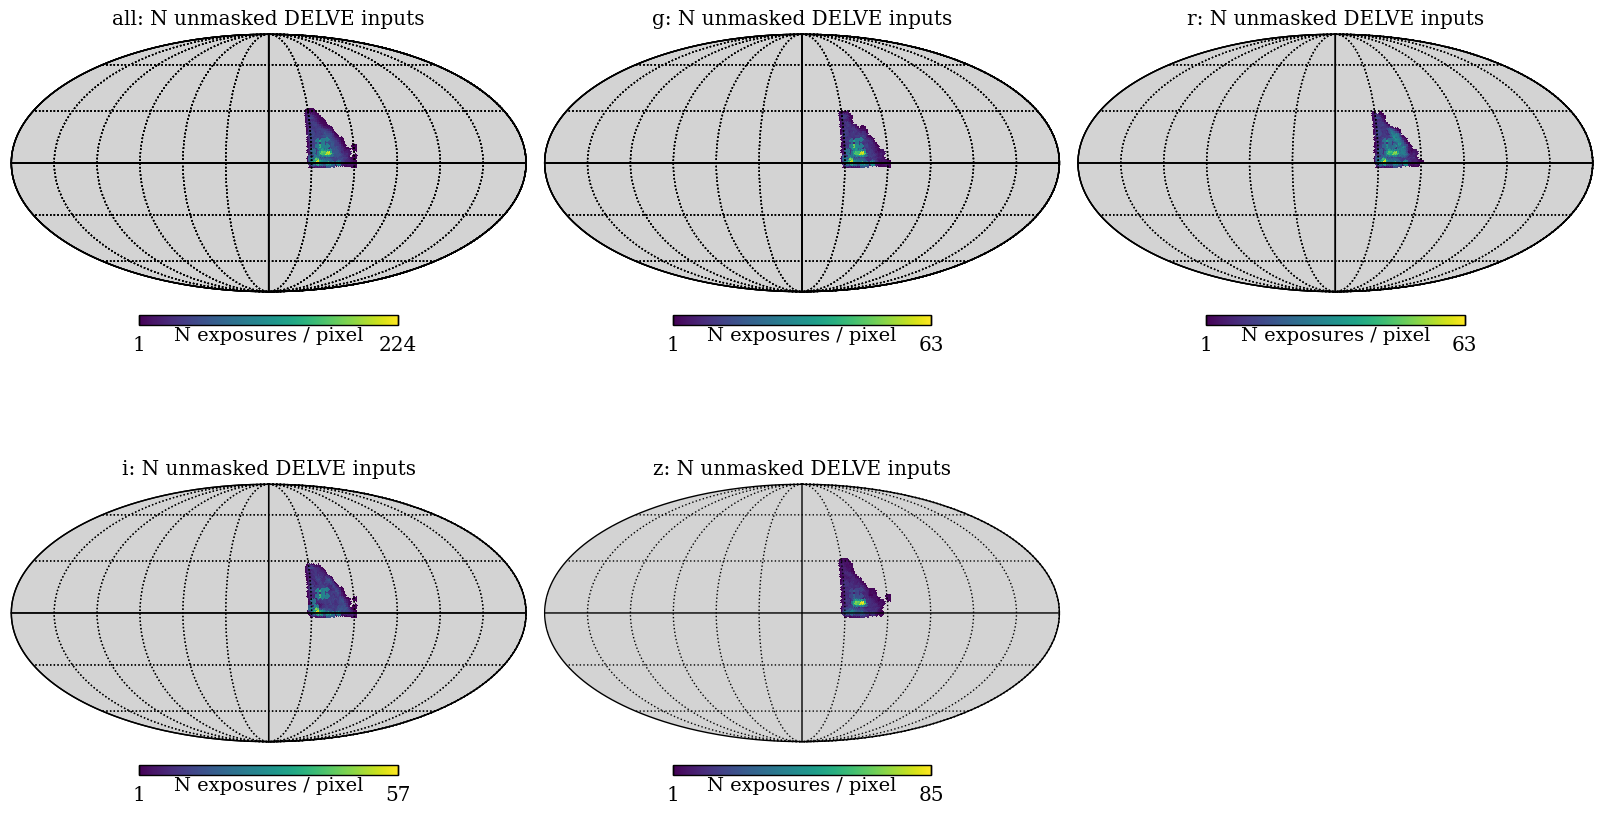

In [11]:

npix = hp.nside2npix(NSIDE)

def count_map(df):
    m = np.zeros(npix)
    for idx in df.index:
        m[footprints[idx]] += 1
    m[m == 0] = hp.UNSEEN
    return m

print(f"{len(sel_df)} exposures kept (SELECTION={SELECTION!r})")
maps = {"all": count_map(sel_df), **{b: count_map(sel_df[sel_df["band"] == b]) for b in BANDS}}

fig = plt.figure(figsize=(16, 9))
for k, (name, m) in enumerate(maps.items(), start=1):
    vmax = m[m != hp.UNSEEN].max() if (m != hp.UNSEEN).any() else 1
    hp.mollview(m, fig=fig.number, sub=(2, 3, k), title=f"{name}: N {SELECTION} DELVE inputs",
                unit="N exposures / pixel", min=1, max=vmax, cmap="viridis", badcolor="lightgrey")
    hp.graticule()


## Save the raw-input list

In [12]:
os.makedirs(OUT_DIR, exist_ok=True)
cols = ["expnum", "unitname", "band", "ra", "dec", "nite", "exptime", "t_eff", "psf_fwhm", "propid", "tag", "flag",
        "path", "hpx", "template_fraction", "template_fraction_max", "template_fraction_mean", "template_masked",
        "in_template_footprint"]
out = sel_df[cols].sort_values(["band", "expnum"]).reset_index(drop=True)
out_path = os.path.join(OUT_DIR, "delve_raw_inputs_in_range.csv")
out.to_csv(out_path, index=False)
print(f"wrote {len(out)} rows to {out_path}")
out.head()

wrote 3936 rows to out_patch0/delve_raw_inputs_in_range.csv


,expnum,unitname,band,ra,dec,nite,exptime,t_eff,psf_fwhm,propid,tag,flag,path,hpx,template_fraction,template_fraction_max,template_fraction_mean,template_masked,in_template_footprint
0,209902,D00209902,g,312.000196,0.000278,20130607,30.0,0.269233,1.713,2013A-0719,DECADE_DR3,0,/data/delve01.b/data/chinyi/dr3qr_skims/cat/de...,24669,0.0,0.0,0.0,False,True
1,209903,D00209903,g,311.999983,-0.000333,20130607,200.0,0.286697,1.666,2013A-0719,DECADE_DR3,0,/data/delve01.b/data/chinyi/dr3qr_skims/cat/de...,24669,0.0,0.0,0.0,False,True
2,209905,D00209905,g,311.999700,-0.000778,20130607,200.0,0.291492,1.661,2013A-0719,DECADE_DR3,0,/data/delve01.b/data/chinyi/dr3qr_skims/cat/de...,24669,0.0,0.0,0.0,False,True
3,229341,D00229341,g,318.353654,0.800472,20130831,90.0,0.497424,1.189,2012B-0001,Y6A1_COADD_INPUT,0,/data/delve01.b/data/chinyi/dr3qr_skims/cat/de...,24162,0.0,0.0,0.0,False,True
4,229342,D00229342,g,321.549571,0.800667,20130831,90.0,0.493465,1.175,2012B-0001,Y6A1_COADD_INPUT,0,/data/delve01.b/data/chinyi/dr3qr_skims/cat/de...,24164,0.0,0.0,0.0,False,True


## Raw image md5sums from NOIRLab (optional)

In [13]:

import requests
from tqdm import tqdm

natroot = "https://astroarchive.noirlab.edu"
adsurl = f"{natroot}/api/adv_search"

def expnum_ranges(expnums, max_span=500):
    """Group sorted expnums into [lo, hi] ranges (the archive's EXPNUM filter takes exactly [lo, hi])."""
    expnums = np.sort(np.unique(expnums))
    ranges, lo = [], expnums[0]
    for prev, e in zip(expnums[:-1], expnums[1:]):
        if e - lo > max_span:
            ranges.append((lo, prev))
            lo = e
    ranges.append((lo, expnums[-1]))
    return ranges

def _query_range(lo, hi):
    jj = {
        "outfields": ["md5sum", "archive_filename", "EXPNUM", "FILTER", "obs_type", "proc_type", "instrument"],
        "search": [
            ["instrument", "decam"],
            ["proc_type", "raw"],
            ["obs_type", "object"],
            ["EXPNUM", int(lo), int(hi)],
        ],
    }
    j = requests.post(f"{adsurl}/find/?limit=10000", json=jj).json()
    if isinstance(j, dict):
        raise RuntimeError(f"NOIRLab query failed for EXPNUM {lo}-{hi}: {j.get('errorMessage', j)}")
    return pd.DataFrame(j[1:])

def find_raw_by_expnum(expnums, max_span=500, workers=8):
    # each request takes several seconds server-side, so run them concurrently
    from concurrent.futures import ThreadPoolExecutor
    ranges = expnum_ranges(expnums, max_span)
    with ThreadPoolExecutor(workers) as ex:
        frames = list(tqdm(ex.map(lambda r: _query_range(*r), ranges), total=len(ranges)))
    return pd.concat(frames, ignore_index=True)

if QUERY_NOIRLAB:
    raw = find_raw_by_expnum(out["expnum"].values)
    raw["expnum"] = raw["EXPNUM"].astype(int)
    raw = raw.drop_duplicates("expnum")
    merged = out.merge(raw[["expnum", "md5sum", "archive_filename"]], on="expnum", how="left")
    print(f"{merged['md5sum'].notna().sum()} of {len(out)} exposures matched to raw files")
    merged.to_csv(os.path.join(OUT_DIR, "delve_raw_inputs_in_range_md5.csv"), index=False)
    with open(os.path.join(OUT_DIR, "delve_raw_md5s.txt"), "w") as f:
        f.write("\n".join(merged["md5sum"].dropna().unique()) + "\n")


100%|██████████| 185/185 [06:42<00:00,  2.18s/it] 


3936 of 3936 exposures matched to raw files
